# Formation prediction and change detection

**Analytical question:** Describe team shape and identify change candidates.

**Stages in this notebook:** Centroid distributions; exploratory line clustering; fixed-template assignment; persistence.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None         # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None    # possession_index from available_possessions near the end
EVENT_ID = None         # actual supplied event_id from available_events, not row number
PLAYER_ID = None        # player_id (string or integer), from metadata
TEAM_ID = None          # team_id; None uses the initial possession team
DURATION_S = 6.0     # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3           # use 1 for every 10 Hz frame; 3 gives a faster preview
FORMATION_WINDOW = 28  # qualifying 30 s defensive window, from available_windows


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(FRAME_ID) if FRAME_ID is not None else int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Center one frame

Understand the subtraction before summarizing distributions.

,player,raw_x,centered_x,centered_y
0,287934,5.39,7.288,-2.059
1,51002,-4.41,-2.512,-5.439
2,51043,-7.32,-5.422,25.301
3,51050,8.65,10.548,-6.399
4,560882,-7.43,-5.532,2.631
5,560983,7.44,9.338,-13.759
6,560986,-2.21,-0.312,-11.229
7,795537,-21.18,-19.282,-2.809
8,797298,-9.27,-7.372,12.111
9,965697,11.36,13.258,1.651


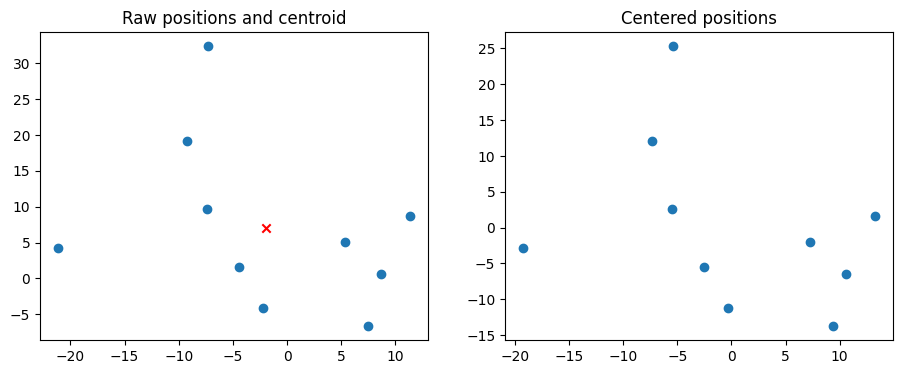

In [5]:
def subtract_centroid(points):
    center=np.asarray(points).mean(axis=0)
    return center,np.asarray(points)-center
one=snapshot[snapshot.team_id.eq(1802)&~snapshot.player_id.isin(keepers)].copy()
center,centered=subtract_centroid(one[['x','y']].to_numpy());display(pd.DataFrame({'player':one.player_id.to_numpy(),'raw_x':one.x.to_numpy(),'centered_x':centered[:,0],'centered_y':centered[:,1]}))
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(one.x,one.y);axs[0].scatter(*center,c='red',marker='x');axs[0].set_title('Raw positions and centroid');axs[1].scatter(centered[:,0],centered[:,1]);axs[1].set_title('Centered positions');plt.show();assert np.allclose(centered.mean(axis=0),0)

## 5. Build player position distributions

Apply the transformation frame by frame, then visualize raw and centered means/covariances on identical samples.

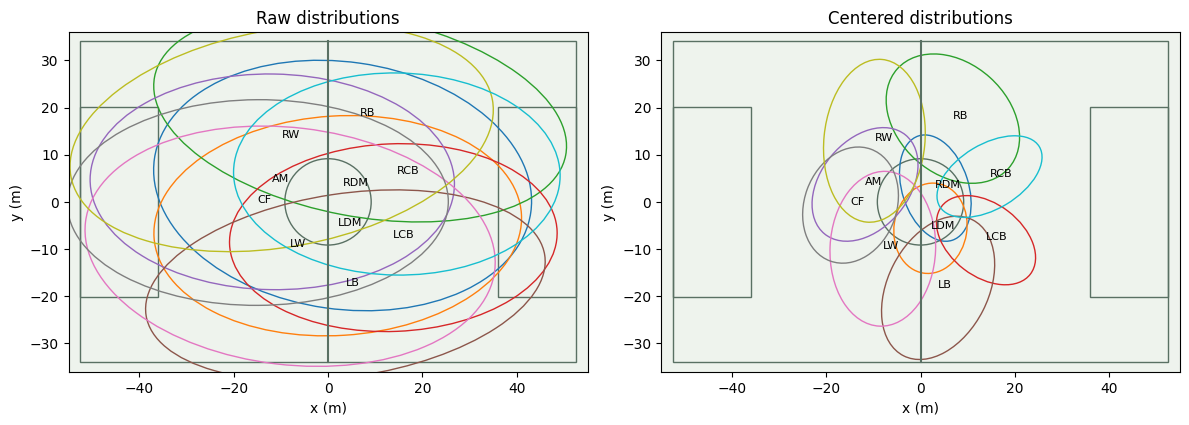

In [6]:
from matplotlib.patches import Ellipse
team=observed[observed.team_id.eq(1802)&~observed.player_id.isin(keepers)].copy()
team[['cx','cy']]=team[['x','y']].to_numpy()-team.groupby(['period_id','frame_id'])[['x','y']].transform('mean').to_numpy()
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,cols,title in zip(axs,[['x','y'],['cx','cy']],['Raw distributions','Centered distributions']):
    pitch(ax);ax.set_title(title)
    for i,(pid,g) in enumerate(team.groupby('player_id')):
        points=g[cols].to_numpy();mean=points.mean(axis=0);vals,vecs=np.linalg.eigh(np.cov(points.T));v=vecs[:,-1]
        ax.add_patch(Ellipse(mean,4*np.sqrt(vals[-1]),4*np.sqrt(vals[0]),angle=np.degrees(np.arctan2(v[1],v[0])),fill=False,color=plt.cm.tab10(i%10)))
        ax.text(*mean,role_labels[pid],fontsize=8)
plt.tight_layout();plt.show()

## 6. Explore longitudinal lines

Clustering helps inspect structure before committing to named formation templates.

,x,y,line
player_id,,,
287934,3.146,3.4380,3
51002,2.145,-5.8020,3
51043,8.083,17.5185,3
51050,14.438,-7.3435,2
560882,-11.833,4.1445,1
560983,4.799,-16.8320,3
560986,-8.318,-11.8075,1
795537,-14.671,-1.5330,1
797298,-10.957,13.2690,1


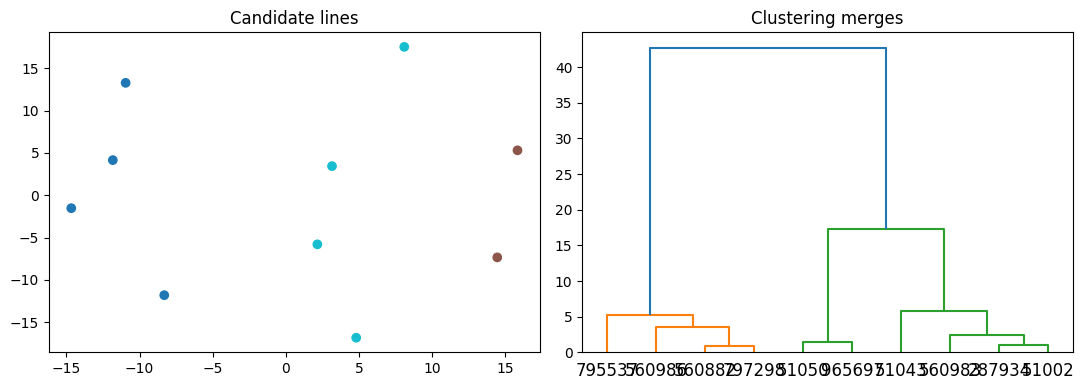

In [7]:
from scipy.cluster.hierarchy import linkage,fcluster,dendrogram
def cluster_lines(points,n_lines=3):
    linkage_matrix=linkage(points[['x']].to_numpy(),method='ward')
    return fcluster(linkage_matrix,n_lines,criterion='maxclust'),linkage_matrix
shape=team.groupby('player_id')[['cx','cy']].median().rename(columns={'cx':'x','cy':'y'})
labels,merges=cluster_lines(shape);display(shape.assign(line=labels))
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(shape.x,shape.y,c=labels,cmap='tab10');axs[0].set_title('Candidate lines');dendrogram(merges,labels=shape.index.tolist(),ax=axs[1]);axs[1].set_title('Clustering merges');plt.tight_layout();plt.show()

## 7. Construct formation templates

Define the model inventory and scale before comparing players with slots.

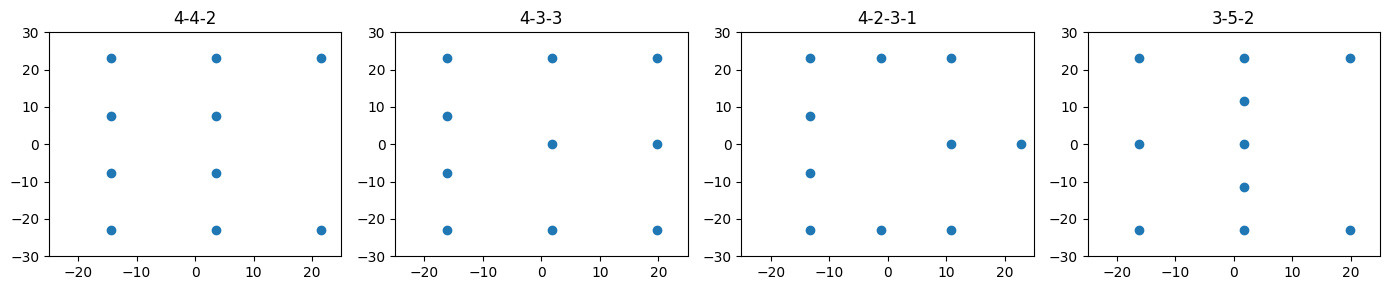

In [8]:
from scipy.optimize import linear_sum_assignment
templates={}
for name,lines in {'4-4-2':[4,4,2],'4-3-3':[4,3,3],'4-2-3-1':[4,2,3,1],'3-5-2':[3,5,2]}.items():
    t=np.array([(x,y) for x,n in zip(np.linspace(-18,18,len(lines)),lines) for y in (np.linspace(-23,23,n) if n>1 else [0])]);templates[name]=t-t.mean(axis=0)
fig,axs=plt.subplots(1,4,figsize=(14,3))
for ax,(name,t) in zip(axs,templates.items()):ax.scatter(t[:,0],t[:,1]);ax.set(title=name,xlim=(-25,25),ylim=(-30,30))
plt.tight_layout();plt.show()

## 8. Inspect one assignment cost matrix

Calculate and inspect pairwise player-slot costs before selecting a formation.

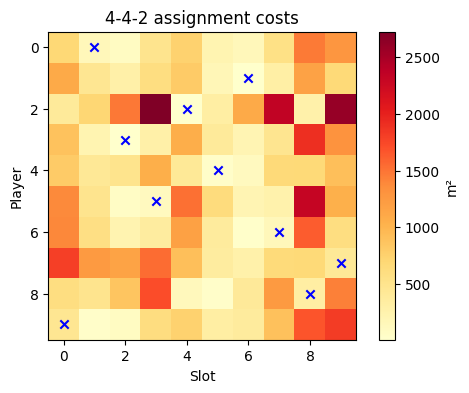

,player_index,slot,residual_m
0,0,1,12.048616
1,1,6,2.479162
2,2,4,2.935010
3,3,2,4.055229
4,4,5,5.393567
5,5,3,10.536599
6,6,7,12.221595
7,7,9,20.323622
8,8,8,17.916649
9,9,0,21.379522


In [9]:
def assignment_costs(points,template):
    centered=points-points.mean(axis=0)
    return ((centered[:,None]-template[None])**2).sum(axis=2)
points=-one[['x','y']].to_numpy();cost=assignment_costs(points,templates['4-4-2']);r,c=linear_sum_assignment(cost)
fig,ax=plt.subplots(figsize=(6,4));im=ax.imshow(cost,cmap='YlOrRd');ax.scatter(c,r,marker='x',c='blue');ax.set(xlabel='Slot',ylabel='Player',title='4-4-2 assignment costs');fig.colorbar(im,ax=ax,label='m²');plt.show()
display(pd.DataFrame({'player_index':r,'slot':c,'residual_m':np.sqrt(cost[r,c])}))

## 9. Compare templates and predict a candidate

Use the inspected cost calculation inside the full scorer.

In [10]:
def score_templates(points):
    fits=[]
    for name,t in templates.items():
        cost=assignment_costs(np.asarray(points),t);r,c=linear_sum_assignment(cost)
        fits.append((name,np.sqrt(cost[r,c].mean()),c))
    return sorted(fits,key=lambda z:z[1])
scores=score_templates(points);display(pd.DataFrame([(name,cost) for name,cost,_ in scores],columns=['candidate','RMS metres']))
assert score_templates(templates['4-3-3'][::-1]+20)[0][1]<1e-10

,candidate,RMS metres
0,4-2-3-1,12.027488
1,4-4-2,12.872421
2,3-5-2,13.140114
3,4-3-3,13.685630


## 10. Score comparable defensive windows

Create the time-series inputs before applying persistence.

In [11]:
team['window']=(team.seconds//30).astype(int);records=[]
for (period,window),g in team[team.team_in_possession.eq(871)].groupby(['period_id','window']):
    per_player=g.groupby('player_id').agg(cx=('cx','median'),cy=('cy','median'),n=('frame_id','size'))
    if len(per_player)!=10 or per_player.n.min()<50:continue
    fits=score_templates(-per_player[['cx','cy']].to_numpy());records.append(dict(period=period,window=window,label=fits[0][0],cost=fits[0][1],margin=fits[1][1]-fits[0][1]))
timeline=pd.DataFrame(records);display(timeline.head(10))

,period,window,label,cost,margin
0,1,1,4-2-3-1,14.533782,1.217760
1,1,4,4-2-3-1,12.106122,1.425694
2,1,5,4-2-3-1,11.858913,0.825284
3,1,7,4-2-3-1,10.126093,1.074907
4,1,8,4-2-3-1,11.115656,1.301365
5,1,9,4-2-3-1,9.273839,1.216594
6,1,12,4-2-3-1,10.309313,0.024867
7,1,16,4-3-3,11.383976,0.049217
8,1,18,4-2-3-1,12.881668,0.539916
9,1,19,4-2-3-1,11.307293,1.123217


### From normalized positions to the assigned formation

This reproduces the chosen slide visual with all calculations and drawing code inline. Subtract the outfield-team centroid **in each frame**, normalize attack direction, then summarize each player by coordinate-wise median over the same defensive window. Ellipses illustrate dispersion, while the matching panel uses medians.

For each fixed template, form the squared-distance cost matrix and use **Hungarian one-to-one assignment**: each of ten players gets one of ten slots, minimizing total squared distance. Compare the optimized **RMS distance** across the four templates. The winner supplies the formation name and role assignment. The right-hand board places players in schematic slots; it does not redraw observed coordinates.

Here we preserve the per-frame centering used on slide 10 and do not subtract a second centroid after taking medians. Coordinate-wise medians need not sum to zero; the single-frame and window-scoring examples above recenter their input as an additional translation adjustment. These are fixed-template estimates, not verified tactical labels.

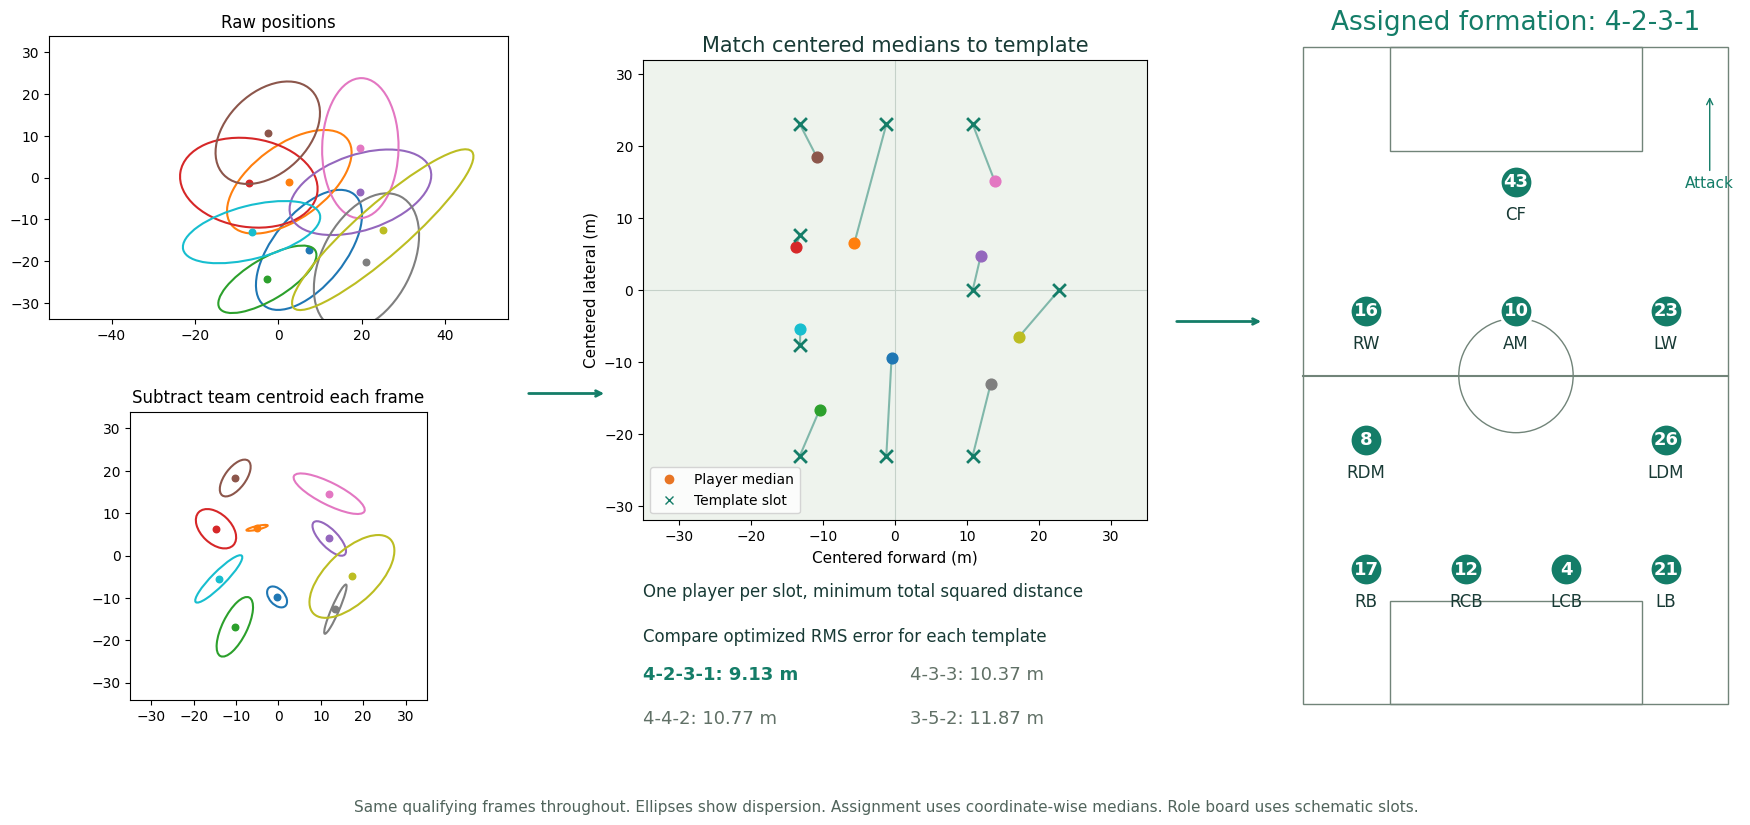

,template,RMS_m
0,4-2-3-1,9.129867
1,4-3-3,10.370057
2,4-4-2,10.768869
3,3-5-2,11.874172


In [12]:
# Same defensive window and assignment as slide 10, computed from tracking here.
lookup={str(p['id']):p for p in metadata['players']}
window=FORMATION_WINDOW  # selected defensive window; home team defending
sample=team[team.period_id.eq(1)&team.window.eq(window)&team.team_in_possession.eq(871)].copy()
med=sample.groupby('player_id').agg(cx=('cx','median'),cy=('cy','median'),n=('frame_id','size'))
assert len(med)==10 and med.n.min()>=50
BG='#fbfcf8';INK='#183a35';GREEN='#147d68';ORANGE='#e87524'
points=-med[['cx','cy']].to_numpy();ids=list(med.index);templates={};line_counts={'4-4-2':[4,4,2],'4-3-3':[4,3,3],'4-2-3-1':[4,2,3,1],'3-5-2':[3,5,2]}
roles={'4-4-2':['RB','RCB','LCB','LB','RW','RCM','LCM','LW','RCF','LCF'],'4-3-3':['RB','RCB','LCB','LB','RCM','CM','LCM','RW','CF','LW'],'4-2-3-1':['RB','RCB','LCB','LB','RDM','LDM','RW','AM','LW','CF'],'3-5-2':['RCB','CB','LCB','RWB','RCM','CM','LCM','LWB','RCF','LCF']}
fits=[]
for label,lines in line_counts.items():
    t=np.array([(x,y) for x,n in zip(np.linspace(-18,18,len(lines)),lines) for y in (np.linspace(-23,23,n) if n>1 else [0])]);t-=t.mean(0);templates[label]=t
    cost=((points[:,None]-t[None])**2).sum(2);rr,cc=linear_sum_assignment(cost);fits.append({'label':label,'rms':float(np.sqrt(cost[rr,cc].mean())),'assignment':cc,'residuals':np.sqrt(cost[rr,cc])})
fits.sort(key=lambda q:q['rms']);best=fits[0];label=best['label'];t=templates[label];cc=best['assignment']
def formation_pitch(ax,vertical=False):
    ax.set_facecolor('#eef3ed')
    if vertical:
        ax.add_patch(Rectangle((-34,-52.5),68,105,fill=False,edgecolor='#718479'));ax.plot([-34,34],[0,0],c='#718479');ax.add_patch(Circle((0,0),9.15,fill=False,edgecolor='#718479'))
        for y in [-52.5,36]:ax.add_patch(Rectangle((-20.16,y),40.32,16.5,fill=False,edgecolor='#718479'))
        ax.set(xlim=(-36,36),ylim=(-54,54),aspect='equal');ax.axis('off')
    else:
        ax.axhline(0,c='#c5d1c9',lw=.8);ax.axvline(0,c='#c5d1c9',lw=.8);ax.set(xlim=(-35,35),ylim=(-32,32),aspect='equal',xlabel='Centered forward (m)',ylabel='Centered lateral (m)')
def formation_board(ax):
    formation_pitch(ax,True);lines=line_counts[label];display_slots=np.array([(y,x) for x,n in zip(np.linspace(-31,31,len(lines)),lines) for y in (np.linspace(-24,24,n) if n>1 else [0])]);colors=plt.get_cmap('Set2')
    for j,(pid,slot) in enumerate(zip(ids,cc)):
        q=display_slots[slot];ax.scatter(*q,s=550,facecolors=GREEN,edgecolors='white',lw=2,zorder=4);ax.text(*q,str(lookup[pid]['number']),ha='center',va='center',color='white',weight='bold',fontsize=13,zorder=5);ax.text(q[0],q[1]-6,roles[label][slot],ha='center',fontsize=12,color=INK)
    ax.annotate('Attack',xy=(31,45),xytext=(31,30),arrowprops={'arrowstyle':'->','color':GREEN},ha='center',fontsize=11,color=GREEN)

# C: link frame centering to the assignment that chooses a formation.
fig=plt.figure(figsize=(18,9));palette=plt.get_cmap('tab10')
rawax=fig.add_axes([.035,.57,.255,.32]);centerax=fig.add_axes([.035,.15,.255,.32]);matchax=fig.add_axes([.365,.34,.28,.53]);scoreax=fig.add_axes([.365,.10,.28,.18]);resultax=fig.add_axes([.725,.13,.25,.76])
for index,(pid,g) in enumerate(sample.groupby('player_id')):
    for ax,cols in [(rawax,['x','y']),(centerax,['cx','cy'])]:
        q=-g[cols].to_numpy();mean=q.mean(0);cov=np.cov(q.T);eig,vec=np.linalg.eigh(cov);angle=np.degrees(np.arctan2(vec[1,-1],vec[0,-1]));ax.add_patch(Ellipse(mean,4*np.sqrt(max(eig[-1],0)),4*np.sqrt(max(eig[0],0)),angle=angle,fill=False,edgecolor=palette(index),lw=1.5));ax.scatter(*mean,s=22,c=[palette(index)])
rawax.set(xlim=(-55,55),ylim=(-34,34),aspect='equal',title='Raw positions')
centerax.set(xlim=(-35,35),ylim=(-34,34),aspect='equal',title='Subtract team centroid each frame')
formation_pitch(matchax)
for j,(pid,q,slot) in enumerate(zip(ids,points,cc)):
    target=t[slot];matchax.plot([q[0],target[0]],[q[1],target[1]],c=GREEN,alpha=.5,lw=1.5)
    matchax.scatter(*q,s=60,c=[palette(j)],zorder=4)
matchax.scatter(*t.T,c=GREEN,marker='x',s=85,lw=2,zorder=5)
matchax.set_title('Match centered medians to template',fontsize=15,color=INK)
matchax.set_xlabel('Centered forward (m)',fontsize=11);matchax.set_ylabel('Centered lateral (m)',fontsize=11);matchax.tick_params(labelsize=10)
from matplotlib.lines import Line2D
matchax.legend(handles=[Line2D([],[],marker='o',ls='',color=ORANGE,label='Player median'),Line2D([],[],marker='x',ls='',color=GREEN,label='Template slot')],fontsize=10,loc='lower left')
scoreax.axis('off');scoreax.text(0,1,'One player per slot, minimum total squared distance',fontsize=12,color=INK,va='top');scoreax.text(0,.72,'Compare optimized RMS error for each template',fontsize=12,color=INK,va='top')
for k,f in enumerate(fits):
    scoreax.text((k%2)*.53,.40-(k//2)*.27,f"{f['label']}: {f['rms']:.2f} m",fontsize=13,color=GREEN if k==0 else '#607066',weight='bold' if k==0 else 'normal')
formation_board(resultax);resultax.set_title('Assigned formation: '+label,fontsize=19,color=GREEN)
for xy,xytext in [((.345,.49),(.30,.49)),((.71,.57),(.66,.57))]:
    rawax.annotate('',xy=xy,xytext=xytext,xycoords=fig.transFigure,textcoords=fig.transFigure,arrowprops={'arrowstyle':'->','color':GREEN,'lw':2},annotation_clip=False)
fig.text(.5,.025,'Same qualifying frames throughout. Ellipses show dispersion. Assignment uses coordinate-wise medians. Role board uses schematic slots.',ha='center',fontsize=11,color='#51645c')
plt.show()


display(pd.DataFrame([{'template':f['label'],'RMS_m':f['rms']} for f in fits]))
if FORMATION_WINDOW==28:assert label=='4-2-3-1' and np.isclose(best['rms'],9.13,atol=.01)


## 11. Final output: persistent change candidates

Missing windows reset candidate evidence. Confirmed labels are retained, without claiming that missing intervals prove stability.

,period,label,cost,margin,confirmed
window,,,,,
1,1.0,4-2-3-1,14.533782,1.217760,None
2,NaN,NaN,NaN,NaN,None
3,NaN,NaN,NaN,NaN,None
4,1.0,4-2-3-1,12.106122,1.425694,None
5,1.0,4-2-3-1,11.858913,0.825284,None
6,NaN,NaN,NaN,NaN,None
7,1.0,4-2-3-1,10.126093,1.074907,None
8,1.0,4-2-3-1,11.115656,1.301365,None
9,1.0,4-2-3-1,9.273839,1.216594,4-2-3-1


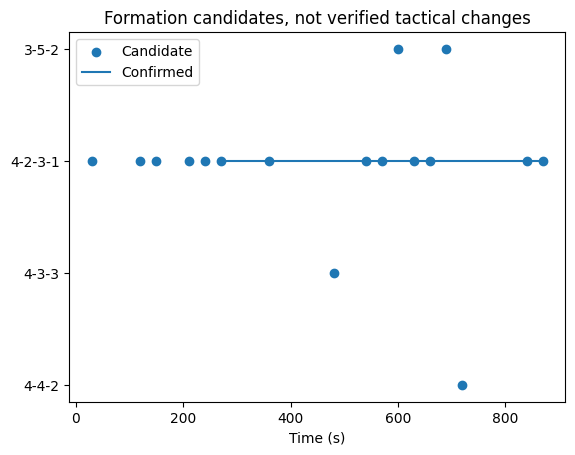

In [13]:
def confirm(sequence,n=3):
    current=None;candidate=None;count=0;result=[]
    for label in sequence:
        if not isinstance(label,str):candidate=None;count=0
        else:
            count=count+1 if label==candidate else 1;candidate=label
            if count>=n:current=candidate
        result.append(current)
    return result
for period,g in timeline.groupby('period'):
    g=g.set_index('window');g=g.reindex(range(int(g.index.min()),int(g.index.max())+1));g['confirmed']=confirm(g.label)
    display(g.head(12));mapping={v:i for i,v in enumerate(templates)}
    plt.scatter(g.index*30,g.label.map(mapping),label='Candidate');plt.plot(g.index*30,g.confirmed.map(mapping),label='Confirmed');plt.yticks(range(4),list(templates));plt.xlabel('Time (s)');plt.title('Formation candidates, not verified tactical changes');plt.legend();plt.show()

## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


,period,window,label,cost,margin
0,1,1,4-2-3-1,14.533782,1.217760
1,1,4,4-2-3-1,12.106122,1.425694
2,1,5,4-2-3-1,11.858913,0.825284
3,1,7,4-2-3-1,10.126093,1.074907
4,1,8,4-2-3-1,11.115656,1.301365
5,1,9,4-2-3-1,9.273839,1.216594
6,1,12,4-2-3-1,10.309313,0.024867
7,1,16,4-3-3,11.383976,0.049217
8,1,18,4-2-3-1,12.881668,0.539916
9,1,19,4-2-3-1,11.307293,1.123217


Recomputed overlays on 20 real frames; first/last: (1, 8481) (1, 8538)


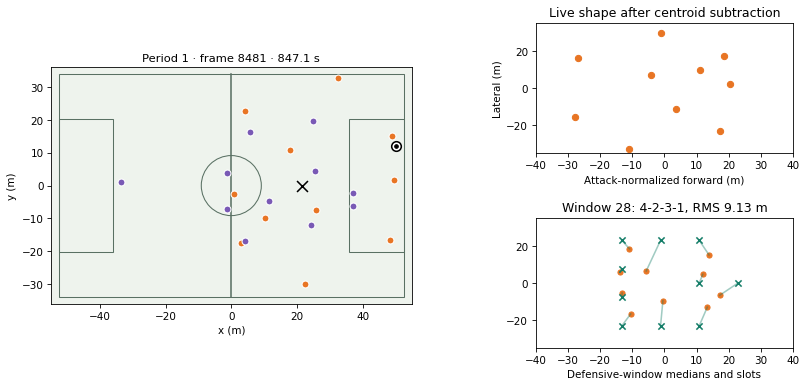

In [14]:
method_name = 'formation'
team_data=team.copy()
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

example_meta={str(p['id']):p for p in metadata['players']}
example_home=int(metadata['home_team']['id']);example_away=int(metadata['away_team']['id'])
example_source=list(raw)
if method_name=='graph_epv':
    example_source=list({(int(r['period']),int(r['frame'])):r for r in [*raw,*goal_sequence] if r.get('period') is not None}.values())
source_frames={(int(r['period']),int(r['frame'])):r for r in example_source if r.get('period') is not None}
frames_by_key={key:r for key,r in source_frames.items() if key[0]==PERIOD and len(r.get('player_data',[]))==22 and all(p.get('x') is not None and p.get('y') is not None for p in r['player_data']) and r.get('ball_data',{}).get('x') is not None and r['ball_data'].get('y') is not None and r.get('timestamp') is not None}
assert frames_by_key,'No complete frames for PERIOD in the cached source.'

def tracking_time(record):
    return pd.to_timedelta(record['timestamp']).total_seconds()

def possession_team(record):
    group=record.get('possession',{}).get('group')
    return example_home if group=='home team' else example_away if group=='away team' else None

def attack_direction(team,period):
    home_left=metadata['home_team_side'][period-1]=='right_to_left'
    return -1 if (home_left if team==example_home else not home_left) else 1

def players_at_frame(key):
    r=frames_by_key[key];previous=source_frames.get((key[0],key[1]-1))
    prior={str(p['player_id']):p for p in previous.get('player_data',[])} if previous else {}
    dt=tracking_time(r)-tracking_time(previous) if previous and previous.get('timestamp') else np.nan
    rows=[]
    for p in r['player_data']:
        pid=str(p['player_id']);old=prior.get(pid,{})
        velocity=np.array([np.nan,np.nan])
        if .05<=dt<=.15 and old.get('x') is not None and old.get('y') is not None:
            velocity=(np.array([p['x'],p['y']])-np.array([old['x'],old['y']]))/dt
        rows.append(dict(player_id=pid,team_id=int(example_meta[pid]['team_id']),x=p['x'],y=p['y'],vx=velocity[0],vy=velocity[1],is_detected=p.get('is_detected')))
    return pd.DataFrame(rows)

def draw_tracking_frame(ax,key):
    r=frames_by_key[key];nodes=players_at_frame(key);pitch(ax)
    for team,color in [(example_home,'#e87524'),(example_away,'#7959b5')]:
        q=nodes[nodes.team_id.eq(team)];ax.scatter(q.x,q.y,c=color,edgecolors='white',s=44,zorder=5)
    ball=np.array([r['ball_data']['x'],r['ball_data']['y']])
    ax.scatter(*ball,s=85,c='white',edgecolors='black',lw=1.5,zorder=10)
    ax.scatter(*ball,s=12,c='black',zorder=11)
    ax.set_title(f'Period {key[0]} · frame {key[1]} · {tracking_time(r):.1f} s',fontsize=11)
    return nodes,ball,r

# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog=[];previous=None;group=None
for key in sorted(frames_by_key):
    r=frames_by_key[key];current_possession_team=possession_team(r)
    continuous=previous is not None and key[1]==previous[1]+1 and 0<tracking_time(r)-tracking_time(frames_by_key[previous])<=.15
    if not continuous or current_possession_team!=group:
        example_catalog.append(dict(possession_index=len(example_catalog),period=key[0],start_frame=key[1],end_frame=key[1],team_id=current_possession_team))
    else:example_catalog[-1]['end_frame']=key[1]
    previous=key;group=current_possession_team
available_possessions=pd.DataFrame(example_catalog)
available_possessions['duration_s']=(available_possessions.end_frame-available_possessions.start_frame+1)/10
available_events=events[events.period.eq(PERIOD)&events.frame_start.isin([k[1] for k in frames_by_key])].copy() if 'events' in globals() else pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):display(available_events[['event_id','event_type','frame_start','frame_end']].head(10))

clip_start_frame=None;clip_stop_frame=None;example_action=None
if method_name=='formation':
    available_windows=timeline[timeline.period.eq(PERIOD)].copy();display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):raise ValueError('FORMATION_WINDOW must be a qualifying window in available_windows.')
    example_window_data=team_data[team_data.period_id.eq(PERIOD)&team_data.window.eq(FORMATION_WINDOW)&team_data.team_in_possession.eq(871)]
    example_med=example_window_data.groupby('player_id')[['cx','cy']].median()
    example_points=-example_med.to_numpy();example_fits=[]
    for name,t in templates.items():
        cost=((example_points[:,None]-t[None])**2).sum(2);rr,cc=linear_sum_assignment(cost)
        example_fits.append((name,float(np.sqrt(cost[rr,cc].mean())),cc))
    example_fits.sort(key=lambda a:a[1]);example_best=example_fits[0]
    candidates=[k[1] for k in frames_by_key if FORMATION_WINDOW*30<=tracking_time(frames_by_key[k])<(FORMATION_WINDOW+1)*30]
    assert candidates,'Selected formation window has no complete animation frames.'
    clip_start_frame=min(candidates);clip_stop_frame=max(candidates)
elif method_name=='events':
    display(passes.reset_index(names='pass_index').head(12))
    if len(passes):
        assert 0<=PASS_INDEX<len(passes),'PASS_INDEX is a row number in passes.'
        example_action=passes.iloc[PASS_INDEX];clip_start_frame=max(int(example_action.release)-8,0);clip_stop_frame=int(example_action.reception)+12
elif method_name=='xt':
    example_actions=events[events.event_type.eq('player_possession')&events.end_type.eq('pass')&events.pass_outcome.eq('successful')&events.period.eq(PERIOD)&events.frame_end.isin([k[1] for k in frames_by_key])].dropna(subset=['x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']).copy()
    display(example_actions[['event_id','frame_end','x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']].head(12))
    assert len(example_actions),'No completed actions with endpoint coverage.'
    example_action=example_actions.iloc[0] if EVENT_ID is None else example_actions[example_actions.event_id.eq(EVENT_ID)].iloc[0]
    clip_start_frame=int(example_action.frame_end)-5
elif method_name=='graph_epv' and SEQUENCE=='goal':
    clip_start_frame=int(goal_sequence[0]['frame']);clip_stop_frame=int(goal_sequence[-1]['frame'])
elif method_name=='graph_epv' and SEQUENCE=='non_goal':
    clip_start_frame=int(non_goal_sequence[0]['frame']);clip_stop_frame=int(non_goal_sequence[-1]['frame'])

if EVENT_ID is not None and method_name!='xt':
    chosen=available_events[available_events.event_id.eq(EVENT_ID)]
    assert len(chosen)==1,'Choose EVENT_ID from available_events.event_id, not a row number.'
    clip_start_frame=int(chosen.frame_start.iloc[0]);clip_stop_frame=int(chosen.frame_end.iloc[0])+10
if POSSESSION_INDEX is not None:
    chosen=available_possessions[available_possessions.possession_index.eq(POSSESSION_INDEX)]
    assert len(chosen)==1,'Choose POSSESSION_INDEX from available_possessions.'
    clip_start_frame=int(chosen.start_frame.iloc[0]);clip_stop_frame=int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame=int(FRAME_ID);clip_stop_frame=None
if clip_start_frame is None:clip_start_frame=int(frame_id)
if (PERIOD,clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible=[k[1] for k in sorted(frames_by_key) if k[1]>=clip_start_frame and (clip_stop_frame is None or k[1]<=clip_stop_frame)]
    assert possible,'No covered frame for this selection.'
    clip_start_frame=possible[0]
clip_keys=[]
for f in range(clip_start_frame,clip_start_frame+max(2,int(DURATION_S*10))):
    key=(PERIOD,f)
    if key not in frames_by_key or (clip_stop_frame is not None and f>clip_stop_frame):break
    if clip_keys and not 0<tracking_time(frames_by_key[key])-tracking_time(frames_by_key[clip_keys[-1]])<=.15:break
    clip_keys.append(key)
assert len(clip_keys)>=2,'Selection ends at a coverage boundary; choose another covered start.'
assert FRAME_STRIDE>=1
clip_keys=clip_keys[::FRAME_STRIDE]
assert len(clip_keys)>=2,'Reduce FRAME_STRIDE or increase clip duration.'
selected_team=TEAM_ID if TEAM_ID is not None else possession_team(frames_by_key[clip_keys[0]]) or example_home
focus_player_id=str(PLAYER_ID) if PLAYER_ID is not None else str(next(p['id'] for p in metadata['players'] if int(p['team_id'])==selected_team))
if method_name=='physical' and PLAYER_ID is None:focus_player_id=str(summary.sort_values('sprint_m',ascending=False).player_id.iloc[0])
example_origin=tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys=clip_keys



def draw_method_overlay(key,ax,bx,cx):
    for a in [ax,bx,cx]:a.clear()
    nodes,ball,r=draw_tracking_frame(ax,key);t=tracking_time(r)-example_origin
    cx.axis('off')
    shape=nodes[nodes.team_id.eq(1802)&~nodes.player_id.isin(keepers)].copy()
    center=shape[['x','y']].mean().to_numpy();q=shape[['x','y']].to_numpy()-center
    ax.scatter(*center,marker='x',s=110,c='black',zorder=9)
    bx.scatter(-q[:,0],-q[:,1],c='#e87524');bx.set(xlim=(-40,40),ylim=(-35,35),title='Live shape after centroid subtraction',xlabel='Attack-normalized forward (m)',ylabel='Lateral (m)')
    cx.axis('on');best_name,best_cost,assignment=example_best;template=templates[best_name]
    cx.scatter(*example_points.T,c='#e87524',s=24);cx.scatter(*template.T,marker='x',c='#147d68')
    for point,slot in zip(example_points,assignment):cx.plot([point[0],template[slot,0]],[point[1],template[slot,1]],c='#147d68',alpha=.4)
    cx.set(xlim=(-40,40),ylim=(-35,35),title=f'Window {FORMATION_WINDOW}: {best_name}, RMS {best_cost:.2f} m',xlabel='Defensive-window medians and slots')

def make_example_figure(key):
    fig=plt.figure(figsize=(11,5.7),dpi=75)
    gs=fig.add_gridspec(2,2,width_ratios=[1.4,1],hspace=.5)
    ax=fig.add_subplot(gs[:,0]);bx=fig.add_subplot(gs[0,1]);cx=fig.add_subplot(gs[1,1])
    draw_method_overlay(key,ax,bx,cx);fig.subplots_adjust(left=.07,right=.97,bottom=.14,top=.9,wspace=.4,hspace=.65);return fig,(ax,bx,cx)

# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0],clip_keys[-1]]:
    example_check_figure,_=make_example_figure(example_check_key);plt.close(example_check_figure)
print('Recomputed overlays on',len(clip_keys),'real frames; first/last:',clip_keys[0],clip_keys[-1])
example_static,_=make_example_figure(clip_keys[0]);plt.show()
example_fig,example_axes=make_example_figure(clip_keys[0])
def update_animation(i):
    draw_method_overlay(clip_keys[i],*example_axes)
animation=FuncAnimation(example_fig,update_animation,frames=len(clip_keys),interval=100*FRAME_STRIDE,repeat=False,blit=False)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10/FRAME_STRIDE,default_mode='once')))


## Interpretation and limitations

Metadata roles are not frame-level role truth. Covariance ellipses show dispersion, not confidence intervals. These fixed templates do not reproduce elastic [EFPI](https://arxiv.org/abs/2506.23843). Formation-change labels require video review. [Pleuler](https://github.com/devinpleuler/research/blob/master/frame-by-frame-position.md) proposed change detection without testing it.